# Модуль 1 ML · Проект №4 — Отмена брони · уровень C

**Постановка:** отель может продать номер повторно, если модель предполагает отмену брони. **Ложноположительная ошибка (FP)** здесь особенно опасна: модель сказала «отменит», а гость приехал. Рекомендуемая метрика — **precision** при консервативном пороге.

По методичке командный ноутбук включает блоки **A → B → C**. Укажите **группу, участников и авторов ячеек** самостоятельно перед сдачей (не выдавайте автоматически созданные материалы за работу участника на занятии).

> Если в `data/hotel_bookings.csv` нет оригинальных 119 390 строк, ноутбук работает на `hotel_bookings_demo.csv` — **искусственно созданном** наборе для проверки. Метрики демонстрации нельзя использовать в отчёте как реальные показатели отеля.

In [1]:
# Блок A — загрузка и окружение (автор ячейки: впишите фамилию)
from pathlib import Path
import sys
import pandas as pd
import numpy as np
from IPython.display import display, Image
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.hotel_project import (MODEL_FEATURES, POST_BOOKING, DROPPED_EXTRAS, TARGET,
    load_data, missing_report, audit_data, split_data, feature_frame, make_pipeline,
    compare_models, threshold_table, choose_threshold, evaluate, group_errors,
    create_eda_figures, save_threshold_figure)
DATA = ROOT/'data'/'hotel_bookings.csv'
if not DATA.exists():
    DATA = ROOT/'data'/'hotel_bookings_demo.csv'
print('ИСТОЧНИК:', DATA.name)
print('ТИП:', 'СИНТЕТИЧЕСКИЙ DEMO' if 'demo' in DATA.name else 'ОТКРЫТЫЙ CSV (119390 строк)')
df = load_data(DATA)
print('Размер:', df.shape)
display(df.head(3))
display(df[TARGET].value_counts(normalize=True).rename('Доля класса').to_frame())

ИСТОЧНИК: hotel_bookings_demo.csv
ТИП: СИНТЕТИЧЕСКИЙ DEMO
Размер: (3500, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,405,2015,June,8,19,0,1,2,0.0,0,SC,PRT,Online TA,Corporate,0,0,0,B,D,0,No Deposit,1.0,NaN,0,Contract,-4.000000,0,0,Check-Out,2017-04-15
1,City Hotel,1,186,2016,June,17,14,3,2,2,0.0,0,SC,PRT,Online TA,Direct,0,0,1,D,G,1,No Deposit,10.0,NaN,1,Group,2000.000000,0,0,Canceled,2017-08-01
2,Resort Hotel,1,436,2016,October,1,22,1,4,0,0.0,0,SC,BRA,Online TA,Direct,0,0,1,F,B,0,No Deposit,NaN,NaN,0,Transient,113.938421,0,1,Canceled,2016-01-01


,Доля класса
is_canceled,
0,0.517714
1,0.482286


## A. Матрица ошибок в терминах бизнеса

| | Реально приехал (`0`) | Реально отменил (`1`) |
|---|---|---|
| Модель предсказала «не отменит» (`0`) | TN — верное решение | FN — упущена возможность продать номер |
| Модель предсказала «отменит» (`1`) | **FP — опасный овербукинг** | TP — верно найденная отмена |

Важно: высокая accuracy не гарантирует низкий FP. Для решения отеля в первую очередь смотрим **precision = TP / (TP + FP)** и объём предсказанных отмен.

In [2]:
# Блок B — EDA: только аудит данных, никаких fit на всём датасете
print('Типы столбцов:')
print(df.dtypes.value_counts().to_string())
print('Аудит качества:')
display(audit_data(df))
print('Пропуски:')
display(missing_report(df))
print('Есть признаки, напрямую кодирующие итог:', [x for x in POST_BOOKING if x in df.columns])

Типы столбцов:
int64      16
object     12
float64     4
Аудит качества:


,проверка,значение
0,строк,3500.000000
1,столбцов,32.000000
2,доля_отмен,0.482286
3,дубликаты_полных_строк,0.000000
4,брони_без_гостей,53.000000
5,отрицательная_цена_adr,1.000000
6,adr_больше_1000,1.000000


Пропуски:


,пропуски,процент
company,3302,94.342857
agent,672,19.200000
country,62,1.771429
children,4,0.114286


Есть признаки, напрямую кодирующие итог: ['reservation_status', 'reservation_status_date', 'assigned_room_type', 'booking_changes', 'days_in_waiting_list', 'total_of_special_requests']


In [3]:
# Блок A/B — до обучения отделяем тест (20%), валидацию (20%), обучение (60%).
train, val, test = split_data(df)
print('Строки train/val/test:', len(train), len(val), len(test))
print('Доли отмен:', [round(x[TARGET].mean(), 4) for x in (train, val, test)])
print('Удалены из модели постфактум-признаки:', POST_BOOKING)
print('Также сознательно исключены:', DROPPED_EXTRAS)
X_train = feature_frame(train)
X_val = feature_frame(val)
X_test = feature_frame(test)
assert not set(POST_BOOKING + DROPPED_EXTRAS + [TARGET]) & set(X_train.columns)
assert X_train.columns.equals(X_val.columns) and X_train.columns.equals(X_test.columns)
print('Признаков для модели:', len(X_train.columns), '|', X_train.columns.tolist())

Строки train/val/test: 2100 700 700
Доли отмен: [np.float64(0.4824), np.float64(0.4814), np.float64(0.4829)]
Удалены из модели постфактум-признаки: ['reservation_status', 'reservation_status_date', 'assigned_room_type', 'booking_changes', 'days_in_waiting_list', 'total_of_special_requests']
Также сознательно исключены: ['company', 'agent', 'arrival_date_week_number', 'adr', 'required_car_parking_spaces']
Признаков для модели: 20 | ['hotel', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'deposit_type', 'customer_type']


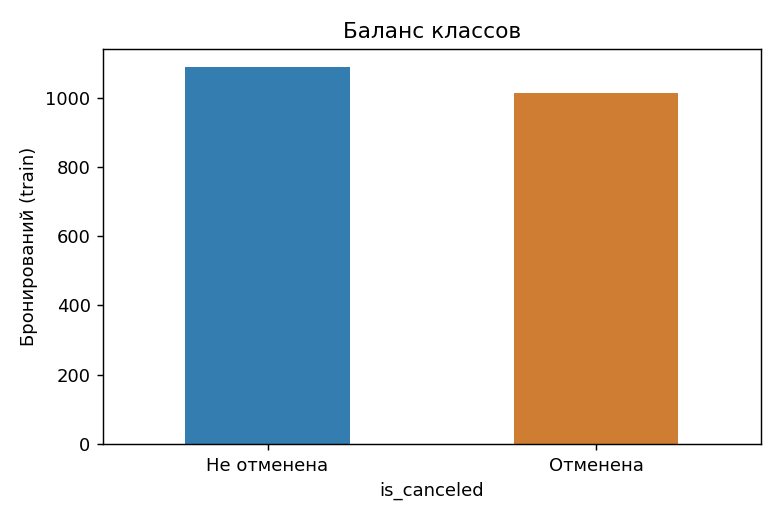

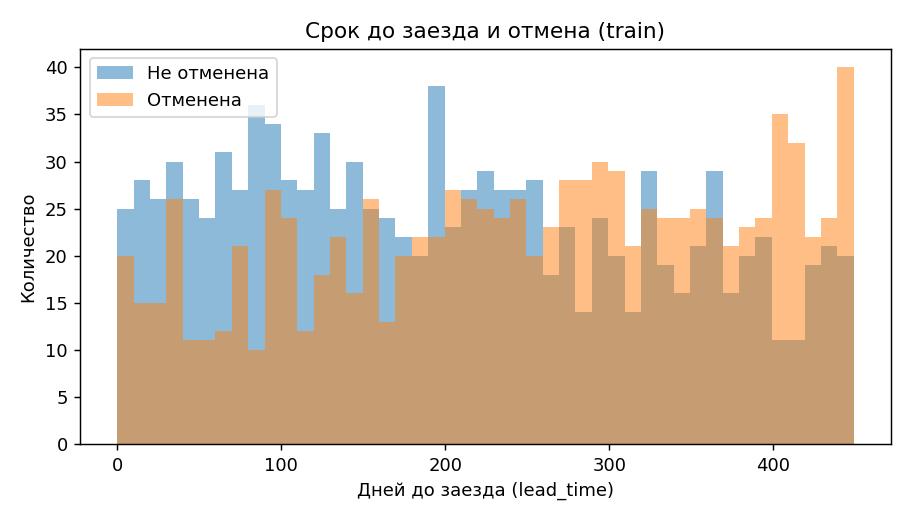

In [4]:
# Блок B — графики только на train; validation/test не изучаем до выбора модели.
FIG = ROOT/'figures'/'notebook'
create_eda_figures(train, FIG)
display(Image(filename=str(FIG/'class_balance.png')))
display(Image(filename=str(FIG/'lead_time_hist.png')))

## B. Выводы EDA и защита от утечки

- `reservation_status` и `reservation_status_date` содержат известный **после завершения** исход: это прямая утечка.
- `assigned_room_type`, `booking_changes`, `days_in_waiting_list`, `total_of_special_requests` могут изменяться после оформления; без снимка полей на момент бронирования исключаем.
- `company` почти полностью пустой; `agent` — идентификатор посредника; `adr` может быть пересчитан после правок. Пока исключаем. `arrival_date_week_number` дублирует информацию о дате.
- В данных встречаются дубли, брони без гостей, отрицательные и экстремальные `adr`. Их **показываем**, но не удаляем без бизнес-обоснования: одинаковые брони не всегда дубли. **Не опираемся на `adr` при обучении**.
- Даже с удалёнными столбцами нужна проверка, доступны ли `previous_cancellations` и остальные исторические признаки *строго на дату бронирования*.

**Ключ:** `SimpleImputer`, `OneHotEncoder` и `StandardScaler` обучаются только внутри `Pipeline.fit(train)` и внутри каждого CV-фолда.

In [5]:
# Блок B — сравнение двух изученных моделей, StratifiedKFold(5) на train.
# ВНИМАНИЕ: весь fit происходит ТОЛЬКО на тренировочных фолдах.
cv_b = compare_models(train, variants=('baseline', 'tree'), n_splits=5)
print('B: baseline LogisticRegression против DecisionTreeClassifier')
display(cv_b)

B: baseline LogisticRegression против DecisionTreeClassifier


,model,cv_pr_auc_mean,cv_pr_auc_std,cv_roc_auc,cv_precision_0_5,cv_recall_0_5
0,baseline,0.589219,0.022386,0.609984,0.562711,0.529147
1,tree,0.546420,0.020754,0.563539,0.529852,0.503443


## C. Два способа борьбы с дисбалансом

1. `class_weight='balanced'`: логистическая регрессия сильнее штрафует ошибку на редком классе.
2. `RandomOverSampler`: дублирует объекты редкого класса **только в тренировочной части каждого фолда** (`imblearn.Pipeline`).

Оба подхода сравниваются с baseline по одинаковому `StratifiedKFold(5)` на train (при идентичных комбинациях признаков используется защищённый от копий `StratifiedGroupKFold(5)`). Нельзя делать oversampling до train/test split или до CV — тогда копии примеров окажутся в validation/test.

In [6]:
# Блок C — две независимые стратегии борьбы с дисбалансом внутри CV
cv_c = compare_models(train, variants=('weighted', 'oversample'), n_splits=5)
cv_results = pd.concat([cv_b, cv_c], ignore_index=True).sort_values('cv_pr_auc_mean', ascending=False)
print('Сравнение без балансировки / class_weight / RandomOverSampler / дерево')
display(cv_results)
winner = str(cv_results.iloc[0]['model'])
print('Лучшая модель по CV PR-AUC:', winner)

Сравнение без балансировки / class_weight / RandomOverSampler / дерево


,model,cv_pr_auc_mean,cv_pr_auc_std,cv_roc_auc,cv_precision_0_5,cv_recall_0_5
2,oversample,0.592089,0.024316,0.611465,0.558967,0.568648
3,weighted,0.589467,0.022925,0.609916,0.556397,0.574555
0,baseline,0.589219,0.022386,0.609984,0.562711,0.529147
1,tree,0.546420,0.020754,0.563539,0.529852,0.503443


Лучшая модель по CV PR-AUC: oversample


Порог: 0.755 | precision>=0.95 на validation? False


,threshold,alerts,TP,FP,precision,recall
51,0.755,20,15,5,0.750000,0.044510
43,0.715,35,26,9,0.742857,0.077151
45,0.725,31,23,8,0.741935,0.068249
50,0.750,23,17,6,0.739130,0.050445
42,0.710,38,28,10,0.736842,0.083086


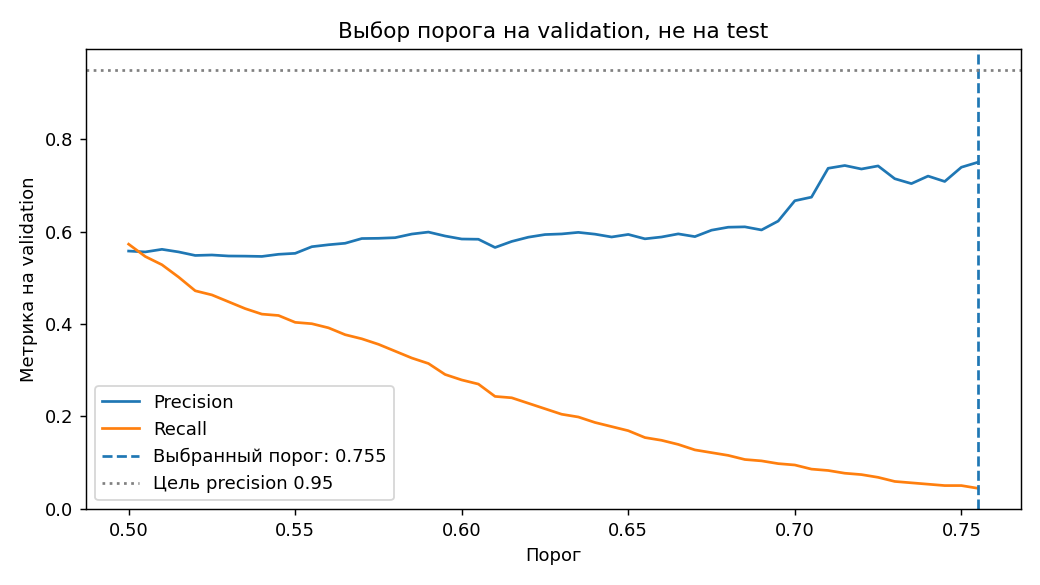

In [7]:
# Блок B/C — выбранный пайплайн обучаем на train, порог подбираем на val.
# Test в подборе модели, балансировке и выборе порога НЕ участвует.
model = make_pipeline(X_train, winner)
model.fit(X_train, train[TARGET])
prob_val = model.predict_proba(X_val)[:, 1]
table = threshold_table(val[TARGET], prob_val, min_alerts=max(20, int(.01*len(val))))
threshold, approved_on_val = choose_threshold(table, target_precision=.95)
print('Порог:', threshold, '| precision>=0.95 на validation?', approved_on_val)
display(table.sort_values('precision', ascending=False).head(5))
save_threshold_figure(table, threshold, FIG)
display(Image(filename=str(FIG/'precision_recall_threshold.png')))

### Почему именно такой порог?

Заказчик опасается **FP**: человек приезжает, а номер перепродан. Поэтому ищем на отдельной validation максимальный recall **при precision не ниже 0.95**, минимум на 1% наблюдений (или 20 бронированиях). Если такой порог не существует, программа помечает решение как **непригодное для автоматического овербукинга**. Даже выполнение этого условия на validation **не является гарантией** безопасной эксплуатации.

Порог 0.95 здесь — **учебная иллюстрация**, а не утверждённый отелем норматив. Для реальной политики нужны цена компенсации, доверительный интервал и проверка на более позднем периоде.

In [8]:
# Блок C — финальная оценка на НЕТРОНУТОМ тесте.
prob_test = model.predict_proba(X_test)[:, 1]
final_default = evaluate(test[TARGET], prob_test, .50)
final_selected = evaluate(test[TARGET], prob_test, threshold)
print('Тест: порог 0.50 против выбранного на validation')
display(pd.DataFrame([final_default, final_selected], index=['default .50','selected']))
print('Матрица ошибок выбранного порога (TN, FP, FN, TP):',
      {k: final_selected[k] for k in ['TN','FP','FN','TP']})

Тест: порог 0.50 против выбранного на validation


,threshold,N,TN,FP,FN,TP,predicted_cancellations,accuracy,precision,recall,f1,pr_auc,roc_auc
default .50,0.500,700,196,166,156,182,348,0.54,0.522989,0.538462,0.530612,0.557618,0.566102
selected,0.755,700,357,5,324,14,19,0.53,0.736842,0.041420,0.078431,0.557618,0.566102


Матрица ошибок выбранного порога (TN, FP, FN, TP): {'TN': 357, 'FP': 5, 'FN': 324, 'TP': 14}


In [9]:
# Блок C — в каких группах ошибаемся чаще?
groups = group_errors(test, prob_test, threshold)
print('Группы с >=30 бронированиями; сравниваем FP/FN, FPR/FNR, precision')
display(groups.query('n >= 30').head(25).round(4))
print('Это аудит групповых ошибок, а не доказательство дискриминации.')

Группы с >=30 бронированиями; сравниваем FP/FN, FPR/FNR, precision


,feature,group,n,FP,FN,precision,false_positive_rate,false_negative_rate,alerts
7,deposit_type,No Deposit,574,1,276,0.7500,0.0034,0.9892,4
8,deposit_type,Non Refund,83,3,36,0.7692,0.0811,0.7826,13
9,deposit_type,Refundable,43,1,12,0.5000,0.0333,0.9231,2
0,hotel,City Hotel,457,5,230,0.7368,0.0235,0.9426,19
1,hotel,Resort Hotel,243,0,94,NaN,0.0000,1.0000,0
6,market_segment,Online TA,325,3,151,0.7692,0.0183,0.9379,13
5,market_segment,Offline TA/TO,140,0,66,1.0000,0.0000,0.9851,1
3,market_segment,Direct,125,1,58,0.6667,0.0154,0.9667,3
4,market_segment,Groups,68,1,29,0.5000,0.0263,0.9667,2
2,market_segment,Corporate,42,0,20,NaN,0.0000,1.0000,0


Это аудит групповых ошибок, а не доказательство дискриминации.


## C. Итог для заказчика и ограничения

1. Любой показанный `precision` получен на тестовом/валидационном срезе, **не гарантирует** отсутствие случаев FP при новом сезоне.
2. Полный Hotel Booking Demand отражает два отеля за 2015–2017 гг., а не любую гостиницу. Нужна **временная** проверка на будущих бронированиях и без идентичных записей между фолдами.
3. Дубликаты могут быть повторными реальными заявками, поэтому удаление без ключа брони может повредить данным. При совпадении всех модельных признаков группы сохраняются целиком в одном разбиении/фолде (StratifiedGroupKFold), чтобы уменьшить риск утечки.
4. Признаки могут пересчитываться после создания брони. Требуется SQL-снимок `as-of-booking` для строгого контроля утечки.
5. Должна быть согласована реальная цена FP и FN; высокая precision может сопровождаться очень низким recall.
6. Даже при хорошем тесте модель **не следует автоматически использовать для овербукинга** без пилотного запуска, мониторинга, калибровки вероятностей, ручного утверждения и процедуры компенсаций.

**Вывод:** это аналитический прототип. Сначала убедиться, что выбранный порог обеспечивает достаточно надёжный прогноз отмен и приемлемую долю ошибок на будущих данных; иначе автоматический овербукинг не запускать.